# DrVI on the RNA of the CRISPR screen

[DrVI](https://github.com/theislab/drvi) learns a representation in which separate biological signals tend to land in separate dimensions. We ran it on raw counts of the 206,091 QC-passing cells, using 4,000 highly variable genes, 32 dimensions and 100 epochs. One run has no batch covariate. The other uses well as a covariate, and because wells are nested within the TNFa condition, that run could remove part of the TNFa signal. We compare both with RNA PCA and with cycleVI `z_other`, and colour every space by the cycleVI clock and the available metadata.

## Main findings

- **DrVI doesn't produce separate clusters here.** All four spaces show one continuous cloud of cells, which is expected from one cell line, and Leiden at resolution 0.5 only cuts that cloud into 2 or 3 parts along the cycle and RNA depth. This notebook has no score yet for whether DrVI separates knockouts or TNFa better than PCA.
- **DrVI does separate signals into dimensions.** In the run without a batch covariate, two dimensions hold most of the clock (dim 31 with 70% of its variance and dim 5 with 47%). Dim 31 runs from G2/M genes (TOP2A, CCNB1) to G1 genes (CD24, ALDH1A1), and dim 5 runs from G2/M genes to G1/S genes (MCM4, CDC6, E2F1). The two dimensions therefore give independent axes of the cycle, without DrVI being told about it.
- **DrVI also finds a TNFa-related response.** Dim 3 and dim 24 contain immediate early and NF-kB genes such as EGR1, IER2, NFKBIA and CXCL8. They rank highest for condition, although their share of variance from condition is still to be read from the heatmap.
- **Well correction changes little.** Well explains under 0.5% of the variance of the top clock dimensions in both runs and wells look mixed in both UMAPs, so the run without a covariate is the simpler default until we've scored TNFa retention.

Cells differ most by RNA depth and cell size in all four spaces, and the highest depth sits at the edge of the cloud. To find finer groups, the next step is to leave out the clock and depth dimensions and cluster on the rest.

In [1]:
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

img = ad.read_h5ad("data/imaging.h5ad")
img = img[~img.obs["qc_fail"].values].copy()
rna = ad.read_h5ad("data/rna.h5ad")
rna = rna[~rna.obs["qc_fail"].values].copy()
rna.layers.clear()
assert (rna.obs_names == img.obs_names).all()
clock = pd.read_csv("mu/cycle_position.csv", index_col=0)
assert (clock.index == rna.obs_names).all()
obs = rna.obs.join(clock)
raw = pd.DataFrame(img.layers["raw"], index=img.obs_names, columns=img.var_names)
wells = obs["Well"].astype(str).values
dna_raw = ((raw["Nucleus_Nuclear"] - raw["Bkg_Nucleus_Nuclear"]) * raw["NuclearArea"]).clip(lower=1)
obs["DNA content (log2)"] = (np.log2(dna_raw) - np.log2(dna_raw).groupby(wells).transform("median")).values
obs["cell area"], obs["nuclear area"] = raw["Area"].values, raw["NuclearArea"].values
obs["log counts"] = np.log1p(obs["rna_total_counts"])
del raw, img
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
rna_hvg = rna[:, pd.read_csv("mu/drvi/nobatch_genes.csv", index_col=0).index]
pca = PCA(32, random_state=0).fit_transform(StandardScaler(with_mean=False).fit_transform(rna_hvg.X).toarray())
spaces = {
    "DrVI, no batch covariate": pd.read_csv("mu/drvi/nobatch_latent.csv", index_col=0).to_numpy(np.float32),
    "DrVI, well as covariate": pd.read_csv("mu/drvi/well_latent.csv", index_col=0).to_numpy(np.float32),
    "cycleVI z_other": pd.read_csv("cyclevi/nobatch400_other.csv", index_col=0).to_numpy(np.float32),
    "RNA PCA": pca,
}
{k: v.shape for k, v in spaces.items()}

{'DrVI, no batch covariate': (206091, 32),
 'DrVI, well as covariate': (206091, 32),
 'cycleVI z_other': (206091, 8),
 'RNA PCA': (206091, 32)}

## UMAPs coloured by the clock and metadata

Each UMAP uses 60,000 random cells, and the same cells appear in every panel. The clock uses a colour map that wraps around, because 0 and 360 degrees are the same point. Non-targeting cells are drawn first so that knockouts stay visible. Leiden clusters are computed separately in each space.

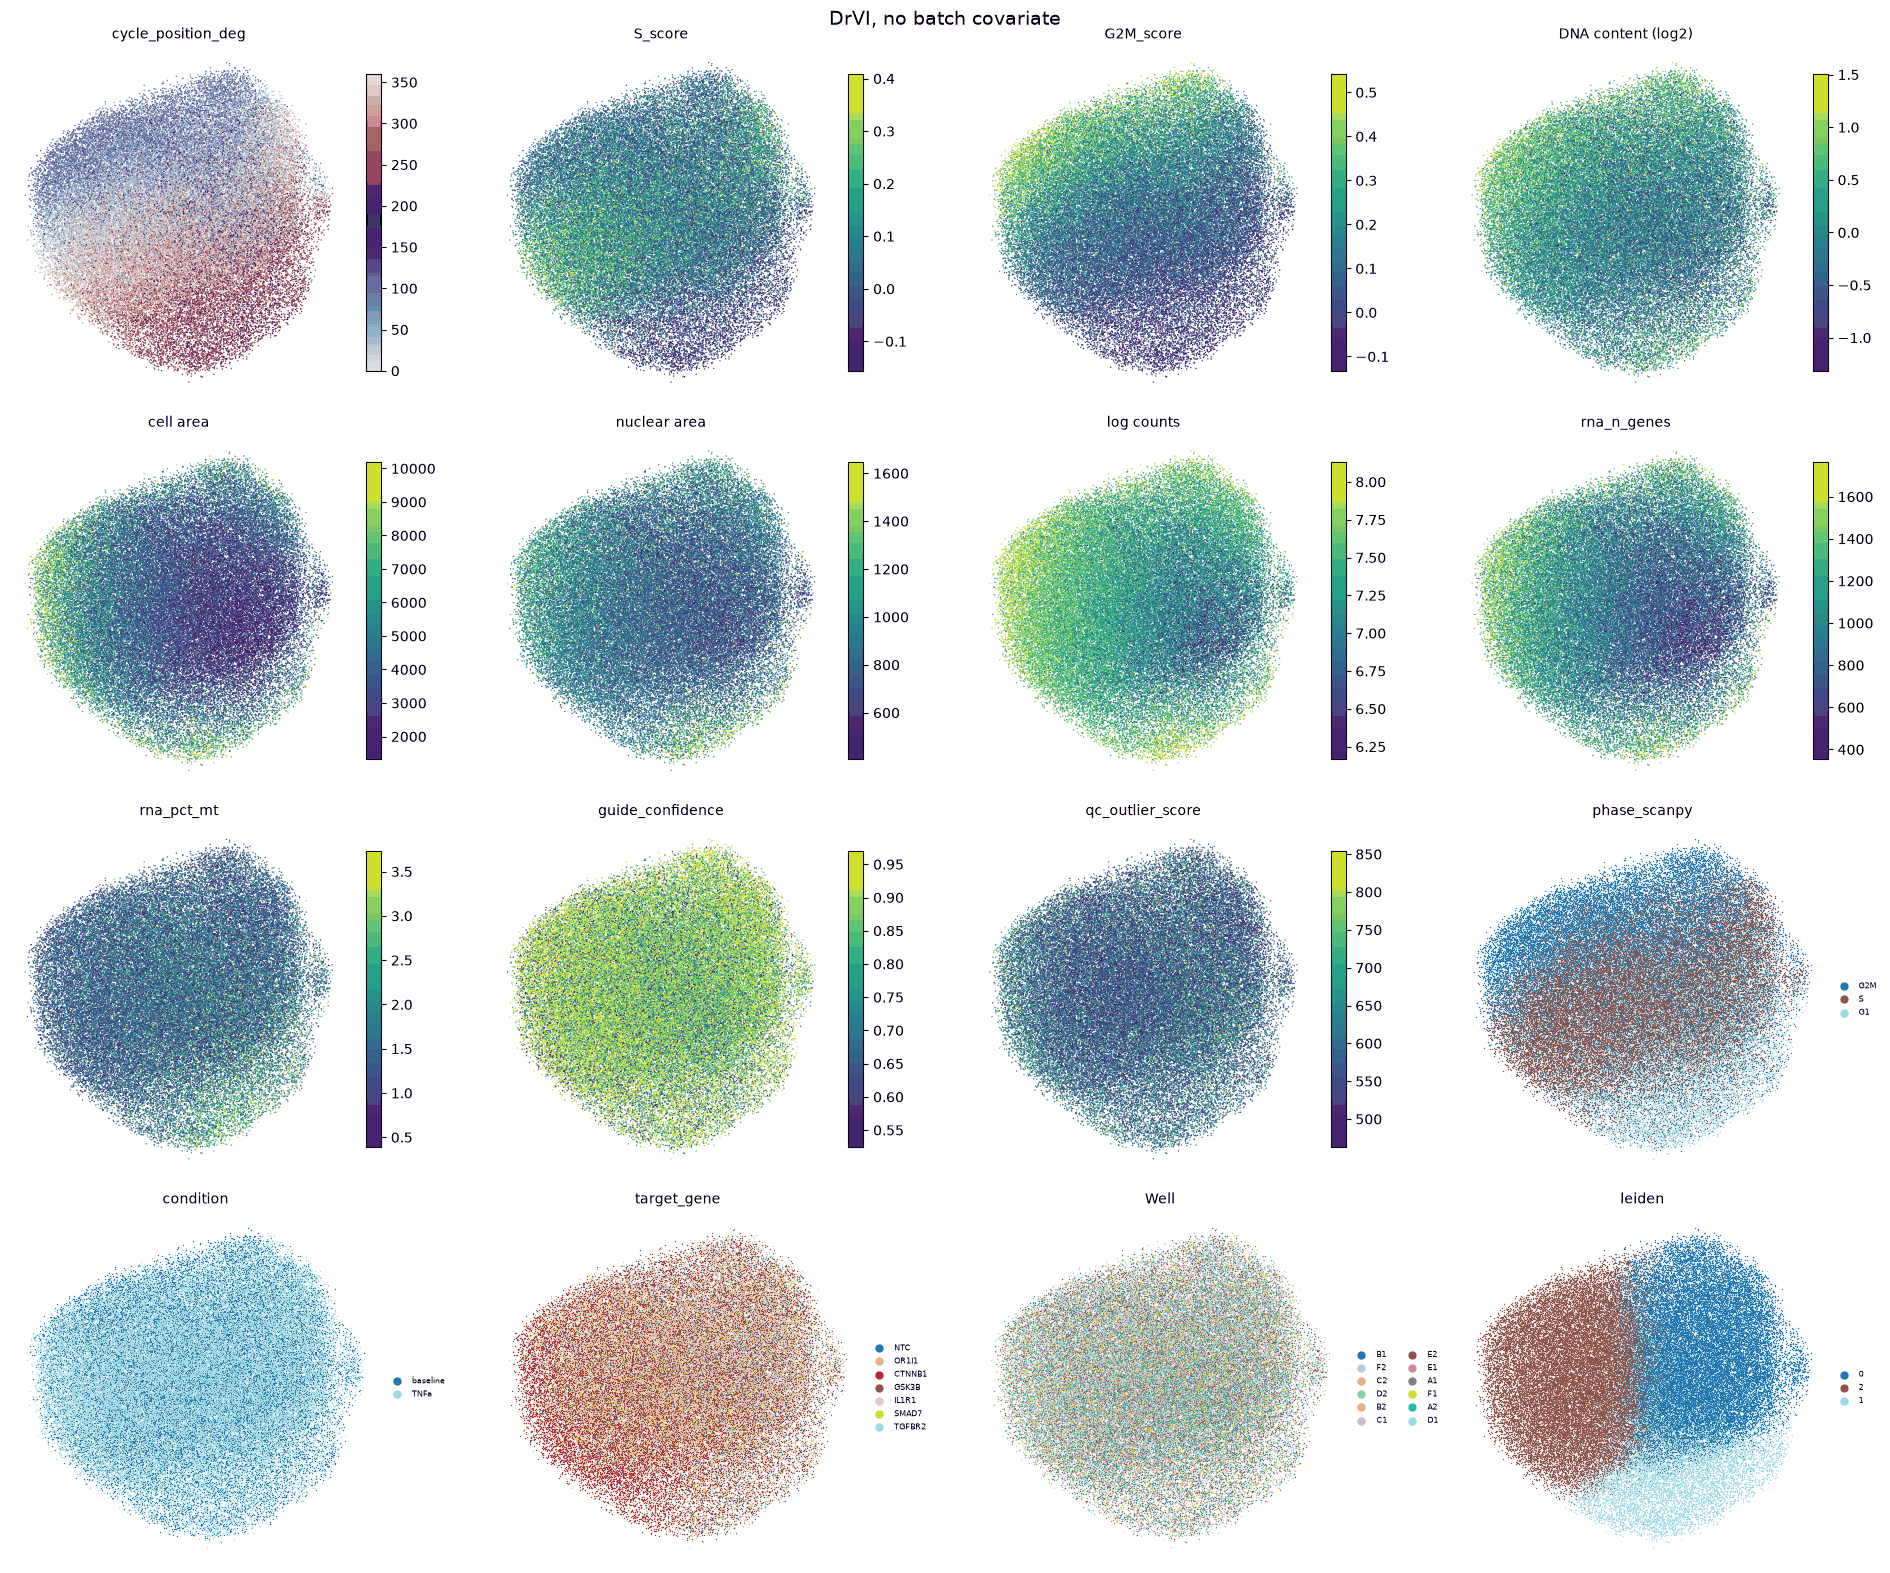

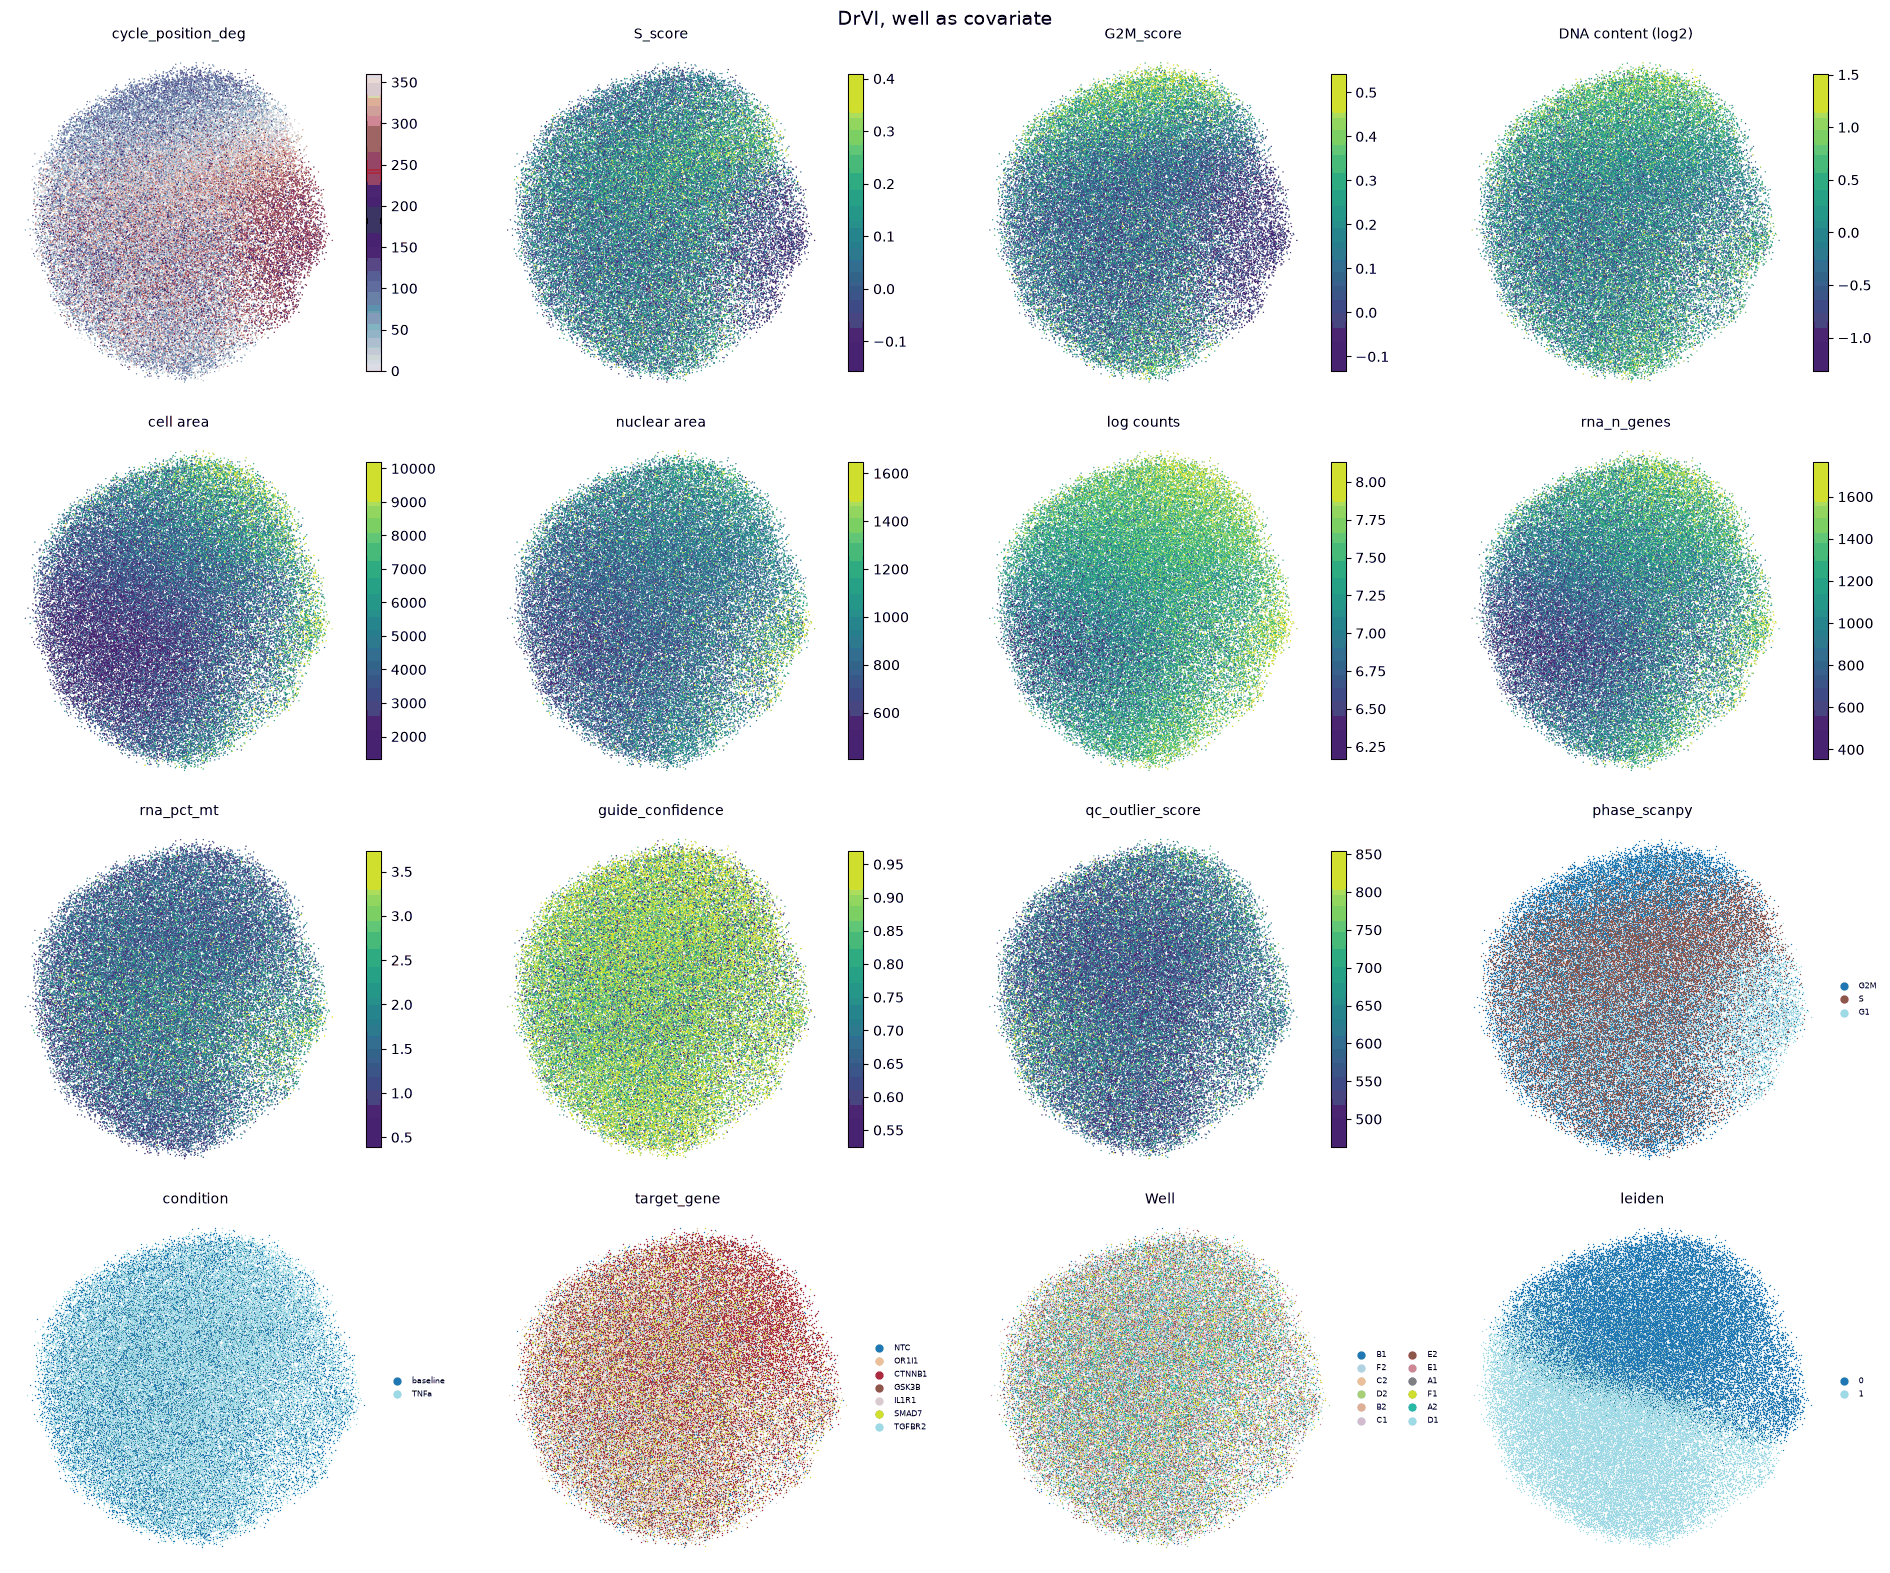

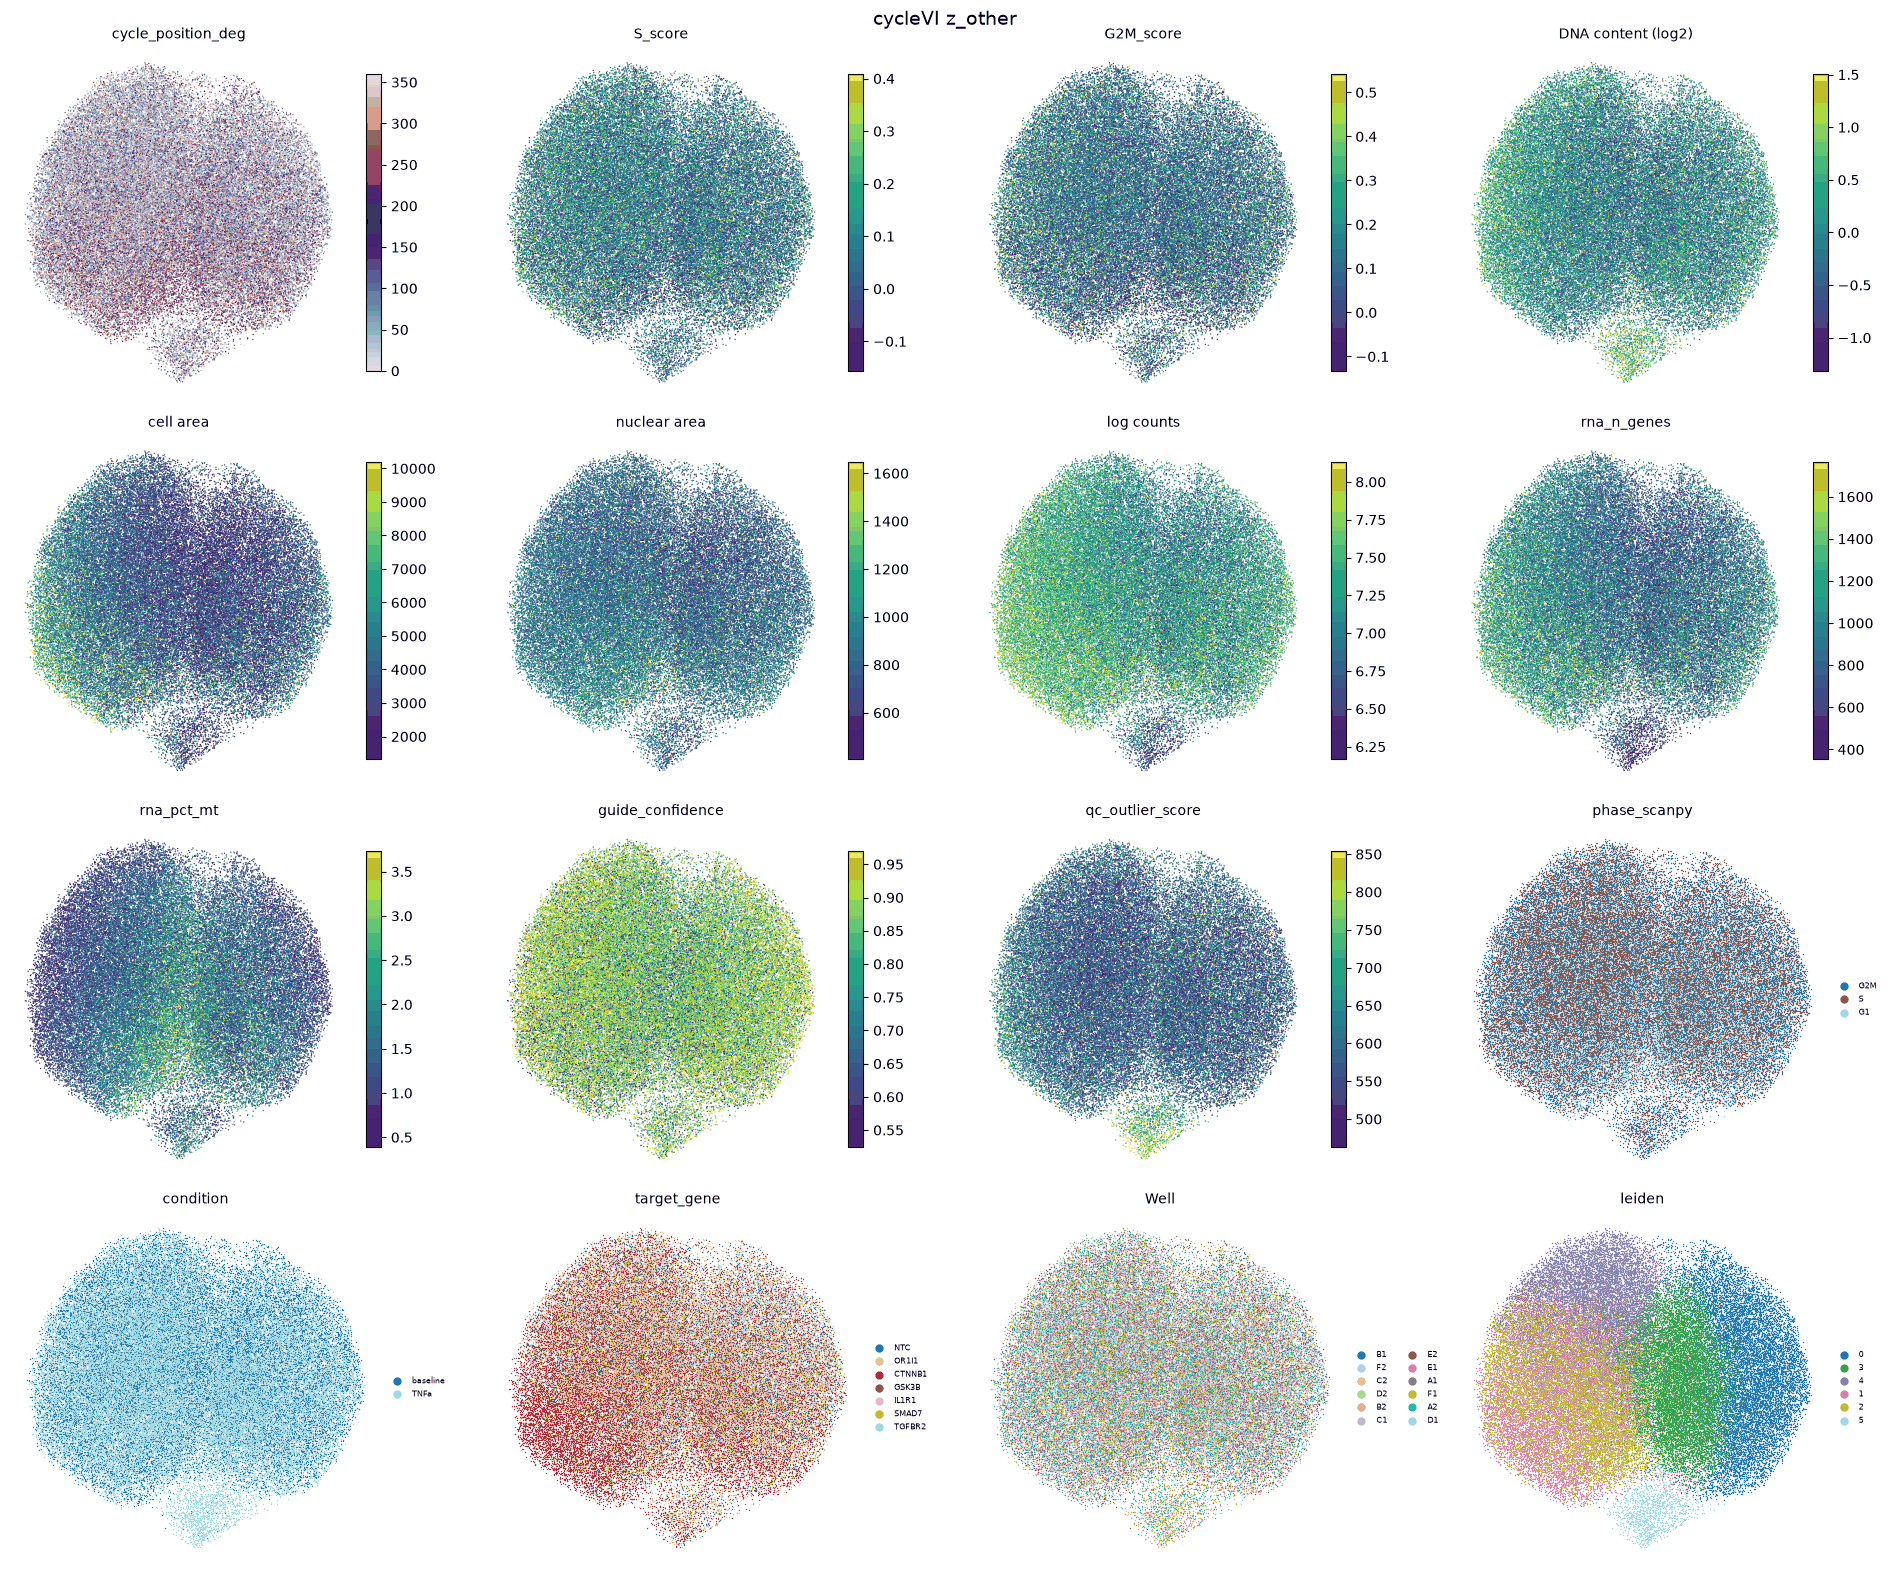

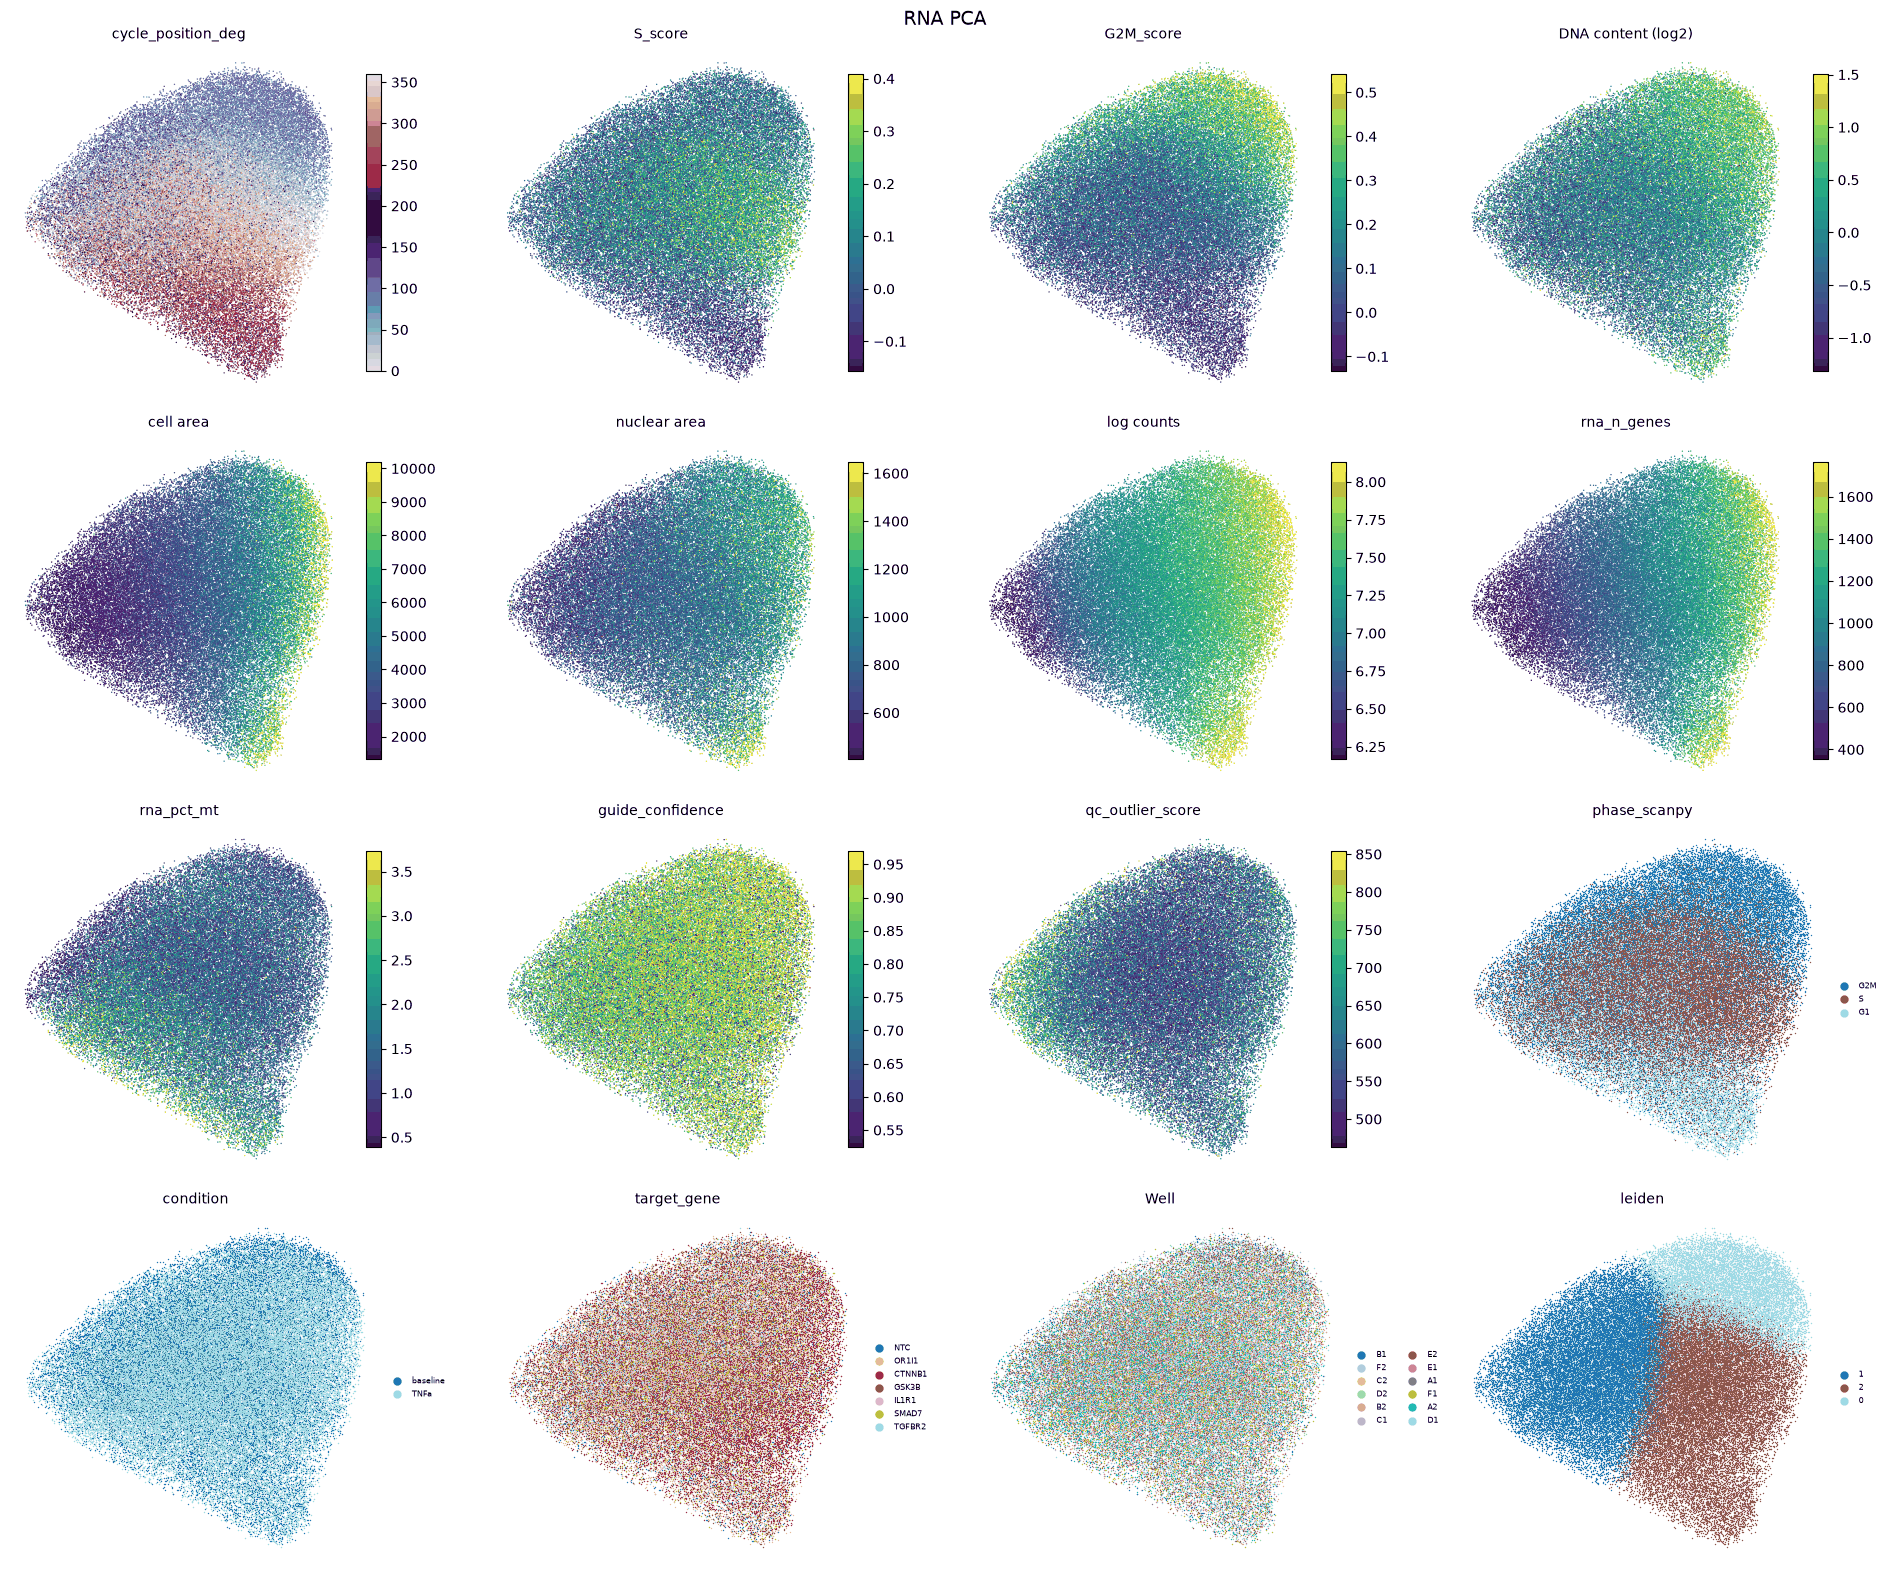

In [2]:
Path("figures").mkdir(exist_ok=True)
sample = np.sort(np.random.default_rng(0).choice(len(obs), 60_000, replace=False))
view = obs.iloc[sample].copy()
CONTINUOUS = {"cycle_position_deg": "twilight", "S_score": "viridis", "G2M_score": "viridis", "DNA content (log2)": "viridis", "cell area": "viridis", "nuclear area": "viridis", "log counts": "viridis", "rna_n_genes": "viridis", "rna_pct_mt": "viridis", "guide_confidence": "viridis", "qc_outlier_score": "viridis"}
CATEGORICAL = ["phase_scanpy", "condition", "target_gene", "Well", "leiden"]


def scatter(ax, xy, column, frame):
    values = frame[column]
    if column in CONTINUOUS:
        order = np.random.default_rng(1).permutation(len(xy))
        limits = (0, 360) if column == "cycle_position_deg" else tuple(np.nanquantile(values.astype(float), [0.01, 0.99]))
        points = ax.scatter(*xy[order].T, c=values.values[order], cmap=CONTINUOUS[column], vmin=limits[0], vmax=limits[1], s=1, linewidths=0, rasterized=True)
        plt.colorbar(points, ax=ax, fraction=0.04)
    else:
        labels = values.astype(str)
        levels = sorted(labels.unique(), key=lambda v: (v != "NTC", (labels == v).sum() * -1))
        colours = plt.get_cmap("tab20")(np.linspace(0, 1, max(len(levels), 2)))
        for colour, level in zip(colours, levels):
            m = (labels == level).values
            ax.scatter(*xy[m].T, color=colour, s=1, linewidths=0, rasterized=True, label=level)
        if len(levels) <= 24:
            ax.legend(markerscale=6, fontsize=6, frameon=False, ncol=2 if len(levels) > 8 else 1, loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_title(column, fontsize=10)
    ax.set(xticks=[], yticks=[])
    ax.spines[["top", "right", "left", "bottom"]].set_visible(False)


layouts = {}
for name, values in spaces.items():
    a = ad.AnnData(X=np.zeros((len(sample), 1), dtype=np.float32), obsm={"X_rep": values[sample]})
    sc.pp.neighbors(a, use_rep="X_rep", transformer="sklearn")
    sc.tl.umap(a, random_state=0)
    sc.tl.leiden(a, flavor="igraph", n_iterations=2, resolution=0.5, random_state=0)
    layouts[name] = (a.obsm["X_umap"], a.obs["leiden"].values)
    frame = view.assign(leiden=a.obs["leiden"].values)
    columns = list(CONTINUOUS) + CATEGORICAL
    fig, axes = plt.subplots(4, 4, figsize=(19, 16))
    for ax, column in zip(axes.ravel(), columns):
        scatter(ax, a.obsm["X_umap"], column, frame)
    fig.suptitle(name, fontsize=14)
    fig.tight_layout()
    plt.show()

## Which DrVI dimensions carry which signal?

Each cell of the heatmap is the share of variance in one DrVI dimension explained by one signal, within wells except for the condition column, which can only be compared between wells. The clock is fitted with its sine and cosine. A dimension with a high clock value is a candidate cell cycle dimension, and leaving those out would give a space without the cycle.

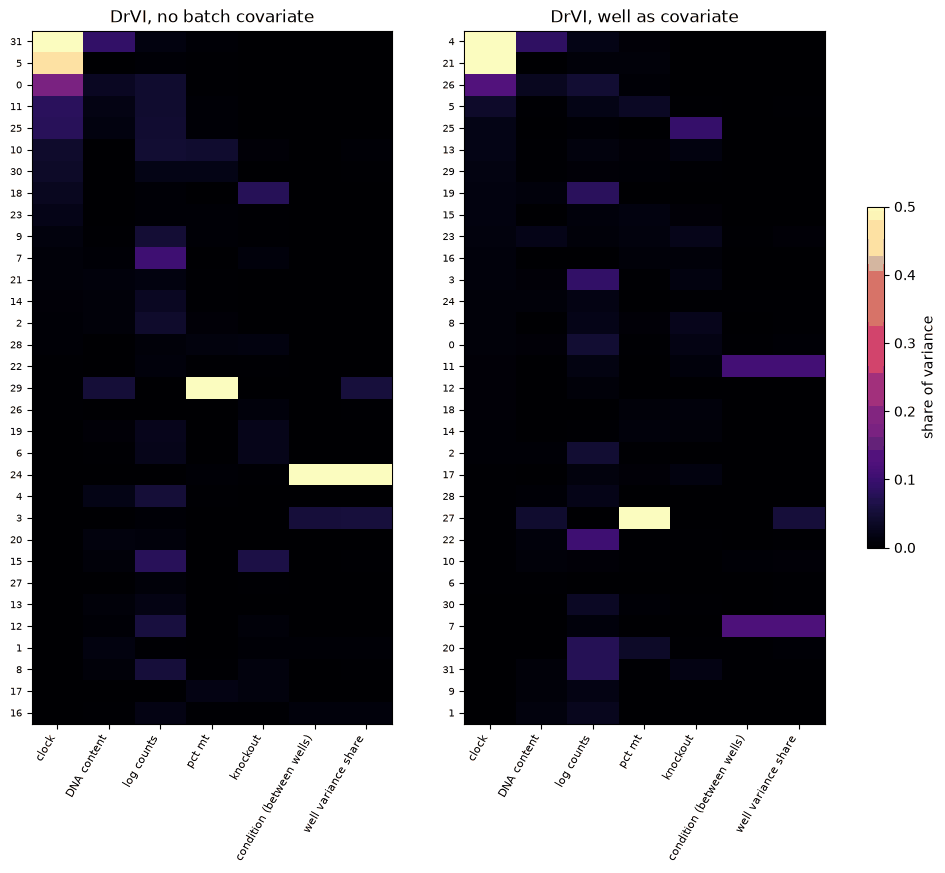

,clock,DNA content,log counts,pct mt,knockout,condition (between wells),well variance share
31,0.704,0.091,0.016,0.006,0.002,0.000,0.001
5,0.469,0.000,0.005,0.003,0.000,0.000,0.000
0,0.178,0.033,0.044,0.002,0.001,0.000,0.001
11,0.082,0.018,0.044,0.005,0.000,0.000,0.001
25,0.080,0.015,0.046,0.006,0.000,0.000,0.001
10,0.042,0.000,0.048,0.045,0.006,0.001,0.004
30,0.037,0.001,0.021,0.021,0.001,0.000,0.004
18,0.031,0.001,0.004,0.000,0.077,0.000,0.001


,clock,DNA content,log counts,pct mt,knockout,condition (between wells),well variance share
4,0.701,0.087,0.021,0.007,0.001,0.000,0.001
21,0.510,0.000,0.009,0.009,0.000,0.000,0.000
26,0.127,0.030,0.047,0.004,0.000,0.000,0.001
5,0.041,0.004,0.021,0.034,0.004,0.002,0.004
25,0.021,0.000,0.006,0.001,0.094,0.000,0.000
13,0.020,0.002,0.012,0.008,0.014,0.000,0.000
29,0.016,0.003,0.007,0.005,0.003,0.000,0.001
19,0.015,0.011,0.082,0.001,0.002,0.000,0.001


In [3]:
def well_centre(values):
    frame = pd.DataFrame(values)
    return (frame - frame.groupby(wells).transform("mean")).to_numpy()


def explained(design, latent):
    design = design - design.mean(0)
    fit = design @ np.linalg.lstsq(design, latent, rcond=None)[0]
    return ((fit - fit.mean(0)) ** 2).sum(0) / np.maximum(((latent - latent.mean(0)) ** 2).sum(0), 1e-9)


angle = np.radians(obs["cycle_position_deg"].values)
known = {
    "clock": well_centre(np.column_stack([np.sin(angle), np.cos(angle)])),
    "DNA content": well_centre(obs[["DNA content (log2)"]].values.astype(float)),
    "log counts": well_centre(obs[["log counts"]].values.astype(float)),
    "pct mt": well_centre(obs[["rna_pct_mt"]].values.astype(float)),
    "knockout": well_centre(pd.get_dummies(obs["target_gene"].astype(str)).values[:, 1:].astype(np.float32)),
}
fig, axes = plt.subplots(1, 2, figsize=(11, 9))
tables = {}
for ax, name in zip(axes, ["DrVI, no batch covariate", "DrVI, well as covariate"]):
    latent = spaces[name]
    table = pd.DataFrame({k: explained(v, well_centre(latent)) for k, v in known.items()})
    table["condition (between wells)"] = explained(pd.get_dummies(obs["condition"].astype(str)).values[:, 1:].astype(np.float32), latent)
    table["well variance share"] = 1 - (well_centre(latent).var(0) / latent.var(0))
    tables[name] = table.sort_values("clock", ascending=False)
    image = ax.imshow(tables[name].values, cmap="magma", vmin=0, vmax=0.5, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(table)), tables[name].index, fontsize=7)
    ax.set_title(name)
fig.colorbar(image, ax=axes, fraction=0.02, label="share of variance")
plt.show()
display(tables["DrVI, no batch covariate"].head(8).round(3))
display(tables["DrVI, well as covariate"].head(8).round(3))

## Do the top genes explain the clock dimensions?

For the DrVI dimensions most tied to the clock and the condition, we list the genes most correlated with the dimension across 30,000 cells. A full interpretation from the decoder comes later.

In [4]:
cells30 = np.sort(np.random.default_rng(2).choice(len(obs), 30_000, replace=False))
genes = rna_hvg.var_names
expression = rna_hvg[cells30].X.toarray()
expression = (expression - expression.mean(0)) / np.maximum(expression.std(0), 1e-6)
table = tables["DrVI, no batch covariate"]
latent = spaces["DrVI, no batch covariate"][cells30]
latent = (latent - latent.mean(0)) / np.maximum(latent.std(0), 1e-6)
correlation = expression.T @ latent / len(cells30)
picks = list(table.index[:4]) + [d for d in table["condition (between wells)"].sort_values(ascending=False).index[:3] if d not in table.index[:4]]
pd.DataFrame({f"dim {d} ({'clock' if d in table.index[:4] else 'condition'})": {"positive": ", ".join(genes[np.argsort(-correlation[:, d])[:12]]), "negative": ", ".join(genes[np.argsort(correlation[:, d])[:12]])} for d in picks}).T

,positive,negative
dim 31 (clock),"PAPPA, CD24, AHNAK2, ALDH1A1, TNS3, S100A4, MX...","TOP2A, UBE2S, PIF1, CCNB1, TUBB4B, MKI67, AURK..."
dim 5 (clock),"ARL6IP1, CCNB1, H2AC6, TUBB4B, RPS27L, SOX4, H...","MCM4, CDC6, E2F1, MCM6, MCM3, PKMYT1, HELLS, M..."
dim 0 (clock),"KPNA2, TOP2A, CCNB1, UBE2S, ARL6IP1, TUBB4B, P...","ADCY6, TNFAIP2, S100A6, CD24, LAMA5, ATP1B1, M..."
dim 11 (clock),"CSKMT, KHDC4, IP6K2, PURPL, LINC-PINT, ZNF761,...","TMPO, RRM2, TOP2A, UBE2S, KPNA2, TUBB4B, H2AZ1..."
dim 24 (condition),"ID1, KRT81, TUBB4B, ENSG00000275180, CSKMT, CA...","CXCL8, IER3, ZFP36, EGR1, NFKBIA, CXCL3, DUSP1..."
dim 3 (condition),"IER2, IER3, EGR1, ZFP36, CXCL8, PPP1R15A, NFKB...","SLC7A5, SLC3A2, ALDH1A1, ITGB1, ARL6IP1, CTSZ,..."
dim 16 (condition),"BHLHE40, CLU, GDF15, ALDH3A1, IER3, CDKN1A, KR...","BDNF, TFAP2A, ENSG00000290883, SNHG3, IL15, CD..."
